# Analysis of Food Price Trends in Kenya
## A Study of Maize and Bean Prices Across Markets

### Introduction
Food prices in Kenya change over time and vary across markets. These changes affect households, traders, and businesses. This project uses real food price data from the World Bank to analyze maize and bean prices across different markets in Kenya using Python data analysis tools.
The findings aim to improve understanding of food price variations in kenya .

### 2. Problem Statement

Changes in food prices can affect the cost of living and the ability of households in Kenya to afford essential food commodities. However, prices may vary over time and across different markets, making it important to understand these changes.

This project addresses the need to analyze historical maize and bean prices to identify price trends, differences between markets, and possible seasonal patterns. Using Python data analysis tools, the project aims to provide insights into food price variations in Kenya.

### Objectives
**Main objective:**  
To analyze maize and bean price trends across different markets in Kenya using Python.

**Specific objectives:**
1. To clean and prepare food price data.
2. To analyze how maize and bean prices change over time.
3. To compare average prices across markets.
4. To visualize price trends using graphs.
5. To identify useful insights from the data.

### 4. Research Questions

This project seeks to answer the following questions:

1. How do maize and bean prices change over time in Kenya?
2. How do price changes compare between maize and beans?
3. How do average maize and bean prices differ across markets?
4. Are there seasonal patterns in maize and bean prices?

### 6. Tools and Technologies

The following tools and libraries are used in this project:

* Python: The programming language used for data analysis.
* Pandas: Used to load, clean, organize, and analyze the dataset.
* NumPy: Used for numerical calculations.
* Matplotlib: Used to create graphs and visualize price trends.
* Jupyter Notebook: Used to combine code, analysis, visualizations, and explanations in one document.

# Importing libraries and load the data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd

df = pd.read_csv("KEN_RTFP_mkt_2007_2026-10-05.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (55692, 46)


,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,price_date,year,...,l_maize_fao,c_maize_fao,inflation_maize_fao,trust_maize_fao,o_food_price_index,h_food_price_index,l_food_price_index,c_food_price_index,inflation_food_price_index,trust_food_price_index
0,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-01-01,2007,...,21.27,22.09,NaN,9.7,0.50,0.53,0.48,0.50,NaN,8.8
1,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-02-01,2007,...,21.41,22.07,NaN,9.7,0.50,0.53,0.48,0.50,NaN,8.8
2,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-03-01,2007,...,20.39,20.39,NaN,9.7,0.50,0.52,0.48,0.49,NaN,8.8
3,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-04-01,2007,...,19.46,20.34,NaN,9.7,0.49,0.52,0.47,0.49,NaN,8.8
4,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-05-01,2007,...,18.63,18.63,NaN,9.7,0.49,0.51,0.46,0.47,NaN,8.8


## 2. Understanding the Dataset

In this section, we explore the dataset to understand its size, columns, and the type of information it contains.

In [3]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of rows and columns: (55692, 46)

Column names:
['ISO3', 'country', 'adm1_name', 'adm2_name', 'mkt_name', 'lat', 'lon', 'geo_id', 'price_date', 'year', 'month', 'currency', 'components', 'start_dense_data', 'last_survey_point', 'data_coverage', 'data_coverage_recent', 'index_confidence_score', 'spatially_interpolated', 'beans', 'livestock_goat_s_fao', 'maize_fao', 'o_beans', 'h_beans', 'l_beans', 'c_beans', 'inflation_beans', 'trust_beans', 'o_livestock_goat_s_fao', 'h_livestock_goat_s_fao', 'l_livestock_goat_s_fao', 'c_livestock_goat_s_fao', 'inflation_livestock_goat_s_fao', 'trust_livestock_goat_s_fao', 'o_maize_fao', 'h_maize_fao', 'l_maize_fao', 'c_maize_fao', 'inflation_maize_fao', 'trust_maize_fao', 'o_food_price_index', 'h_food_price_index', 'l_food_price_index', 'c_food_price_index', 'inflation_food_price_index', 'trust_food_price_index']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 55692 entries, 0 to 55691
Data columns (total 46 columns):
 #   Column   

## 3. Checking Missing Values

Missing values are records where information is not available. We check them to understand the quality and completeness of our dataset.

In [4]:
missing_values = df.isnull().sum()

print("Columns with the most missing values:")
print(missing_values.sort_values(ascending=False).head(10))

Columns with the most missing values:
beans                             53868
livestock_goat_s_fao              53091
maize_fao                         52647
inflation_beans                    2808
inflation_food_price_index         2808
inflation_maize_fao                2808
inflation_livestock_goat_s_fao     2808
lat                                 238
lon                                 238
mkt_name                              0
dtype: int64


## 4. Data Cleaning

In this step, we prepare the maize price data by converting dates into the correct format and removing records where maize prices are missing.

In [5]:
df["price_date"] = pd.to_datetime(df["price_date"])

maize_data = df.dropna(subset=["maize_fao"]).copy()

print("Original number of rows:", len(df))
print("Rows with maize prices:", len(maize_data))
print("Missing maize prices after cleaning:", maize_data["maize_fao"].isna().sum())

maize_data[["price_date", "adm1_name", "mkt_name", "maize_fao"]].head()

Original number of rows: 55692
Rows with maize prices: 3045
Missing maize prices after cleaning: 0


,price_date,adm1_name,mkt_name,maize_fao
9556,2010-01-01,Embu,Embu-Mbeere,34.0
9557,2010-02-01,Embu,Embu-Mbeere,23.0
9558,2010-03-01,Embu,Embu-Mbeere,18.0
9559,2010-04-01,Embu,Embu-Mbeere,16.0
9560,2010-05-01,Embu,Embu-Mbeere,16.0


## 5. Exploratory Data Analysis 

Exploratory Data Analysis helps us understand patterns, distributions, and trends in the data using statistical calculations and visualizations.

In [6]:
print("Summary statistics for maize prices:")
print(maize_data["maize_fao"].describe().round(2))

Summary statistics for maize prices:
count    3045.00
mean       48.22
std        17.58
min         6.00
25%        36.00
50%        45.00
75%        57.00
max       132.00
Name: maize_fao, dtype: float64


### 5.1 Market Price Comparison

In this section, we calculate the average maize price for each market and identify the markets with the highest average prices.

In [7]:
market_prices = maize_data.groupby("mkt_name")["maize_fao"].mean()

highest_markets = market_prices.sort_values(ascending=False).head(10)

print("Top 10 markets with the highest average maize prices:")
print(highest_markets.round(2))

Top 10 markets with the highest average maize prices:
mkt_name
Lodwar (Turkana)          67.47
Mandera                   64.71
Garissa town (Garissa)    62.22
Garissa                   61.10
Wajir town                58.44
Hola (Tana River)         51.18
Kajiado                   51.08
Isiolo town               50.82
Hola town                 50.35
Marsabit                  46.85
Name: maize_fao, dtype: float64


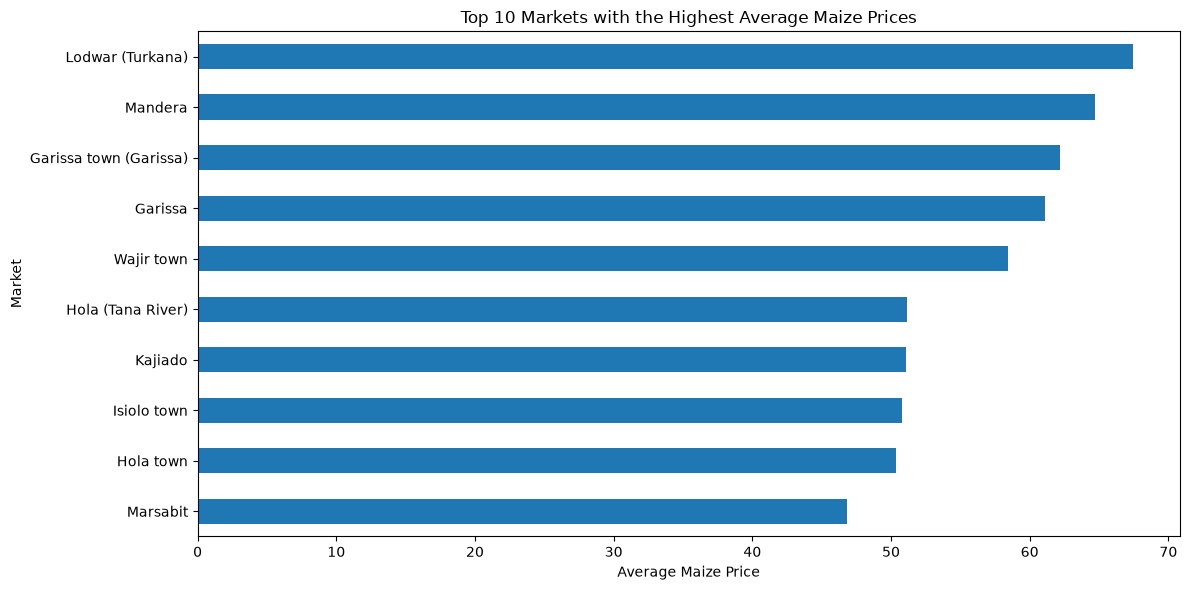

In [8]:
plt.figure(figsize=(12, 6))

highest_markets.sort_values().plot(kind="barh")

plt.title("Top 10 Markets with the Highest Average Maize Prices")
plt.xlabel("Average Maize Price")
plt.ylabel("Market")
plt.tight_layout()
plt.show()

### 5.2 Markets with the Lowest Average Maize Prices

This analysis identifies the markets with the lowest average maize prices in the dataset.

In [9]:
lowest_markets = market_prices.sort_values().head(10)

print("Top 10 markets with the lowest average maize prices:")
print(lowest_markets.round(2))

Top 10 markets with the lowest average maize prices:
mkt_name
Kitui                34.72
Meru                 36.29
Tharaka Nithi        38.69
Embu-Mbeere          38.88
Makueni              39.75
Lamu                 40.21
Taita Taveta         41.61
Kilifi               43.31
Kwale                44.72
Marigat (Baringo)    45.96
Name: maize_fao, dtype: float64


### 5.3 Average Maize Prices Over Time

This analysis calculates the average maize price for each year to identify changes in prices over time.

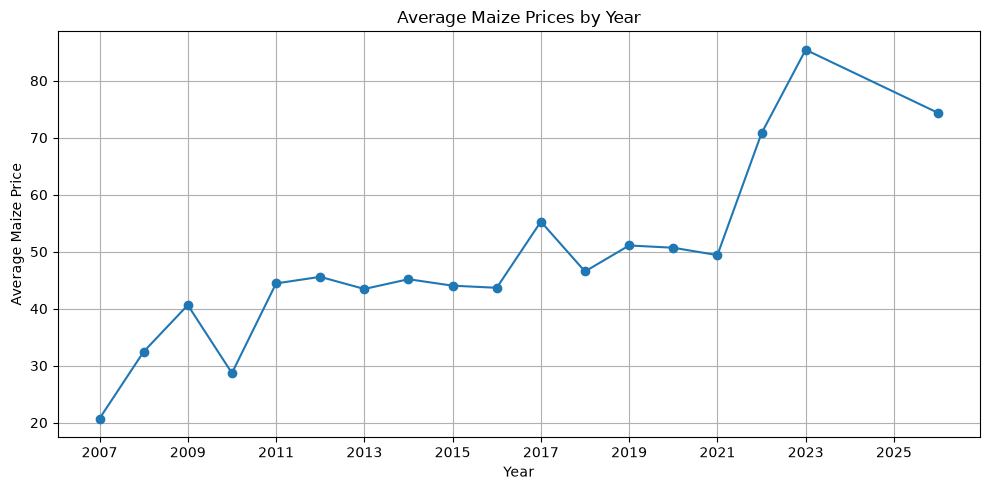

In [10]:
yearly_prices = maize_data.groupby(
    maize_data["price_date"].dt.year
)["maize_fao"].mean()

plt.figure(figsize=(10, 5))
plt.plot(yearly_prices.index, yearly_prices.values, marker="o")

plt.title("Average Maize Prices by Year")
plt.xlabel("Year")
plt.ylabel("Average Maize Price")
plt.xticks(range(
    int(yearly_prices.index.min()),
    int(yearly_prices.index.max()) + 1,
    2
))
plt.grid(True)
plt.tight_layout()
plt.show()

## 6. Bean Price Analysis

In this section, we examine available bean price records to understand price patterns and compare average prices across markets.

In [11]:
bean_data = df.dropna(subset=["beans"]).copy()

print("Number of available bean price records:", len(bean_data))
print("Missing bean prices after cleaning:", bean_data["beans"].isna().sum())

bean_data[["price_date", "adm1_name", "mkt_name", "beans"]].head()

Number of available bean price records: 1824
Missing bean prices after cleaning: 0


,price_date,adm1_name,mkt_name,beans
2548,2021-01-01,Coast,Bangladesh (Mombasa),80.00
2550,2021-03-01,Coast,Bangladesh (Mombasa),100.00
2551,2021-04-01,Coast,Bangladesh (Mombasa),106.36
2555,2021-08-01,Coast,Bangladesh (Mombasa),111.33
2556,2021-09-01,Coast,Bangladesh (Mombasa),106.00


### 6.1 Average Bean Prices Over Time

This analysis calculates the average bean price for each year to identify how prices have changed over time.

In [12]:
yearly_bean_prices = bean_data.groupby(
    bean_data["price_date"].dt.year
)["beans"].mean()

print(yearly_bean_prices.round(2))

price_date
2007     34.92
2008     62.92
2009     65.83
2010     51.25
2011     78.86
2012     78.54
2013     82.57
2014     83.99
2015     88.04
2016     80.91
2017    100.10
2018     85.11
2019     94.04
2020     96.17
2021    104.96
2022    127.08
2023    170.03
2024    154.99
2025    132.92
2026    135.13
Name: beans, dtype: float64


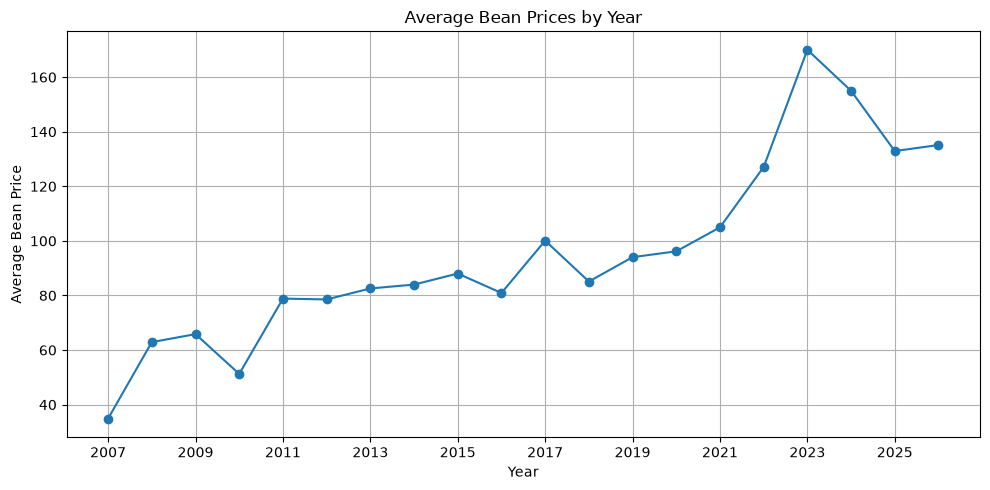

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_bean_prices.index,
    yearly_bean_prices.values,
    marker="o"
)

plt.title("Average Bean Prices by Year")
plt.xlabel("Year")
plt.ylabel("Average Bean Price")

plt.xticks(range(
    int(yearly_bean_prices.index.min()),
    int(yearly_bean_prices.index.max()) + 1,
    2
))

plt.grid(True)
plt.tight_layout()
plt.show()

### 6.2 Markets with the Highest Average Bean Prices

In [14]:
bean_market_prices = bean_data.groupby("mkt_name")["beans"].mean()

highest_bean_markets = bean_market_prices.sort_values(
    ascending=False
).head(10)

print("Top 10 markets with the highest average bean prices:")
print(highest_bean_markets.round(2))

Top 10 markets with the highest average bean prices:
mkt_name
HongKong (Kakuma)        153.65
Kakuma 4                 147.78
Kakuma 3                 145.94
Mogadishu (Kakuma)       143.89
Ethiopia (Kakuma)        142.68
Kalobeyei (Village 2)    139.16
Kakuma 2                 138.86
Kalobeyei (Village 1)    136.86
Dagahaley (Daadab)       133.89
IFO (Daadab)             129.83
Name: beans, dtype: float64


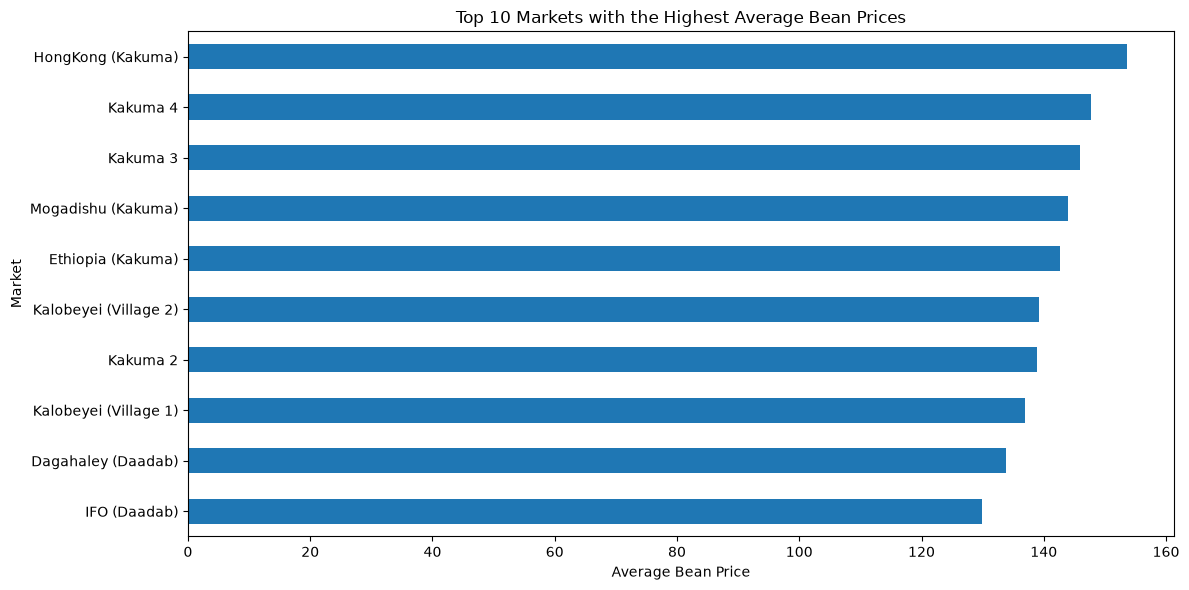

In [15]:
plt.figure(figsize=(12, 6))

highest_bean_markets.sort_values().plot(kind="barh")

plt.title("Top 10 Markets with the Highest Average Bean Prices")
plt.xlabel("Average Bean Price")
plt.ylabel("Market")

plt.tight_layout()
plt.show()

### 6.3 Markets with the Lowest Average Bean Prices

In [16]:
lowest_bean_markets = bean_market_prices.sort_values().head(10)

print("Top 10 markets with the lowest average bean prices:")
print(lowest_bean_markets.round(2))

Top 10 markets with the lowest average bean prices:
mkt_name
Meru                       78.12
Kitui                      79.40
Embu-Mbeere                94.78
Marigat town (Baringo)     95.00
Kajiado                    96.32
Shonda (Mombasa)           98.78
Dandora (Nairobi)          99.05
Junda (Mombasa)            99.66
Makueni                   100.28
Taita Taveta              101.51
Name: beans, dtype: float64


## 7. Comparing Maize and Bean Prices Over Time

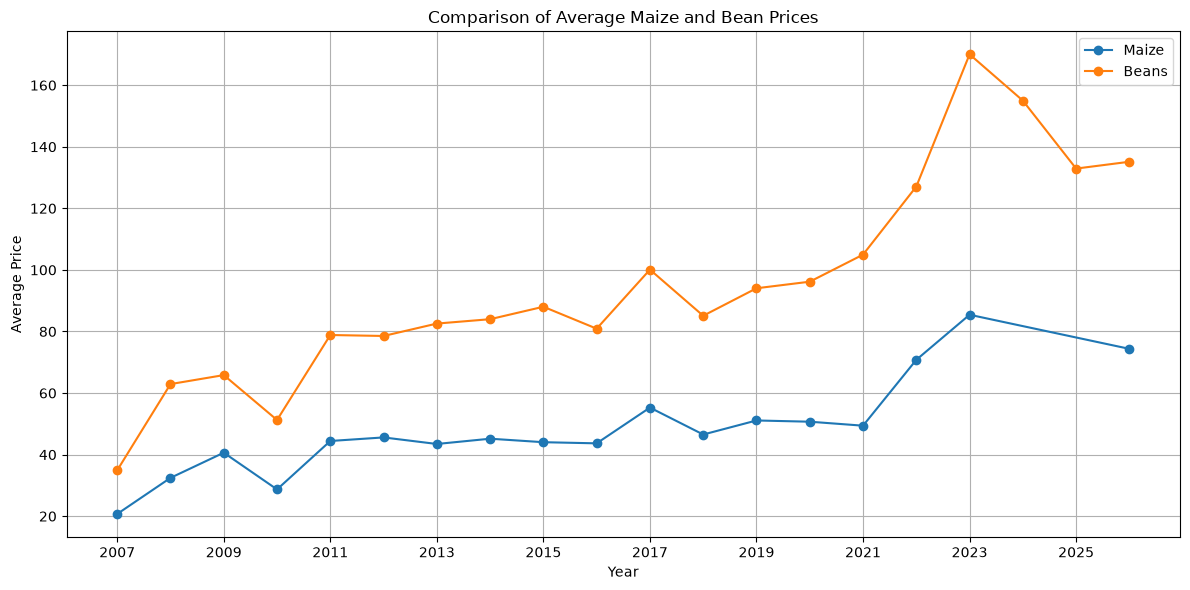

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_prices.index,
    yearly_prices.values,
    marker="o",
    label="Maize"
)

plt.plot(
    yearly_bean_prices.index,
    yearly_bean_prices.values,
    marker="o",
    label="Beans"
)

plt.title("Comparison of Average Maize and Bean Prices")
plt.xlabel("Year")
plt.ylabel("Average Price")

plt.xticks(range(
    int(min(yearly_prices.index.min(), yearly_bean_prices.index.min())),
    int(max(yearly_prices.index.max(), yearly_bean_prices.index.max())) + 1,
    2
))

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 8. Summary Statistics for Maize and Beans

In [18]:
print("Maize Price Statistics:")
print(maize_data["maize_fao"].describe().round(2))

print("\nBean Price Statistics:")
print(bean_data["beans"].describe().round(2))

Maize Price Statistics:
count    3045.00
mean       48.22
std        17.58
min         6.00
25%        36.00
50%        45.00
75%        57.00
max       132.00
Name: maize_fao, dtype: float64

Bean Price Statistics:
count    1824.00
mean      111.54
std        33.94
min        23.00
25%        90.00
50%       105.00
75%       128.00
max       215.00
Name: beans, dtype: float64


# seasonal analysis of food prices

Average Maize Prices by Month:
month
1     49.48
2     46.52
3     45.66
4     47.28
5     48.70
6     50.02
7     50.25
8     48.73
9     47.48
10    47.95
11    48.19
12    48.37
Name: maize_fao, dtype: float64

Average Bean Prices by Month:
month
1     109.40
2     108.99
3     110.90
4     110.60
5     111.61
6     115.17
7     113.25
8     110.52
9     111.71
10    109.99
11    114.88
12    111.78
Name: beans, dtype: float64


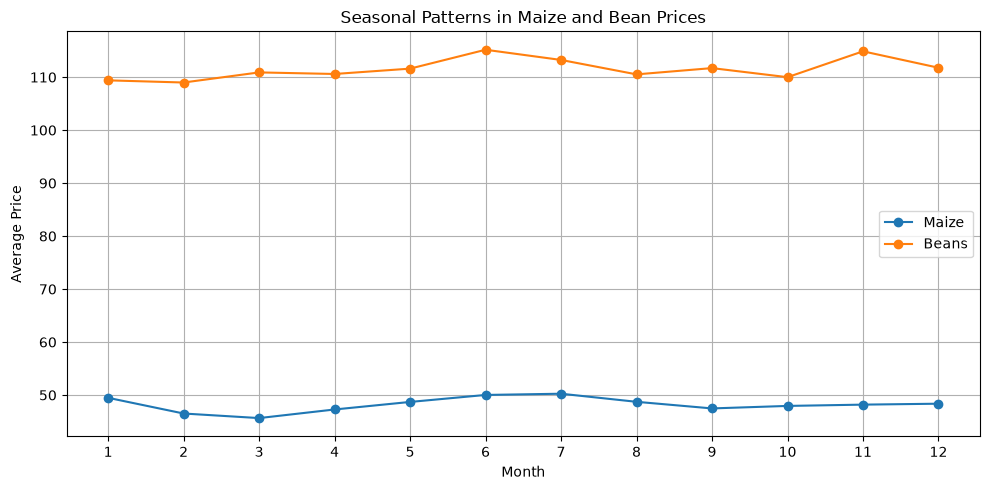

In [19]:
# Extract the month from the price date
maize_data["month"] = maize_data["price_date"].dt.month
bean_data["month"] = bean_data["price_date"].dt.month

# Calculate average prices for each month
monthly_maize_prices = maize_data.groupby("month")["maize_fao"].mean()
monthly_bean_prices = bean_data.groupby("month")["beans"].mean()

# Display monthly averages
print("Average Maize Prices by Month:")
print(monthly_maize_prices.round(2))

print("\nAverage Bean Prices by Month:")
print(monthly_bean_prices.round(2))

# Plot both seasonal patterns
plt.figure(figsize=(10, 5))

plt.plot(monthly_maize_prices.index, monthly_maize_prices.values,
         marker="o", label="Maize")

plt.plot(monthly_bean_prices.index, monthly_bean_prices.values,
         marker="o", label="Beans")

plt.title("Seasonal Patterns in Maize and Bean Prices")
plt.xlabel("Month")
plt.ylabel("Average Price")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Key Findings

The analysis of maize and bean prices across markets in Kenya aims to identify patterns and differences in food prices over time.

The main areas examined are:

1. Price trends: How average maize and bean prices change over the years.
2. Market differences: Which markets have the highest and lowest average prices.
3. Price variation: How much prices differ across markets and over time.
4. Data availability: The number of available price records for maize and beans.



###  Conclusion

This project uses real food price data from the World Bank to analyze maize and bean prices across different markets in Kenya.

Python libraries, including Pandas, NumPy, and Matplotlib, are used to clean the data, calculate summary statistics, compare market prices, and visualize price trends.

This can help us understand how food prices vary across markets and over time. The findings are based on the available records in the dataset, and missing data may limit some comparisons.

### 10. Project Limitations

The project has the following limitations:

1. Missing data: Some records do not contain maize or bean prices, reducing the amount of data available for analysis.
2. Unequal data coverage: Maize and bean prices have different numbers of available records, which may affect comparisons between the two commodities.
3. Limited commodities: The analysis focuses only on maize and beans and does not represent all food prices in Kenya.
4. Market coverage: The dataset includes selected markets, so the results may not represent every market in the country.
5. Limited explanation of price changes: The analysis identifies price patterns but does not establish the causes of price changes.

### 11. Recommendations

1. Monitor food prices: Regular analysis can help identify changes in maize and bean prices over time.
2. Improve data completeness: More complete price records would support more reliable analysis and comparisons between markets.
3. Expand future analysis: Future studies could include more food commodities and markets across Kenya.